# Milton: all eight HRRR fields through DATM (`florida_storm_004hrrrFull`)

Run the cells from top to bottom. This short **00–03 UTC, 9 October 2024 plumbing test** uses HRRR f00 analyses at 00–04 UTC, on the cropped native Lambert grid. The 04 UTC record supplies a right-hand interpolation buffer. All eight DATM streams use the same HRRR file and HRRR source ESMF mesh. The ATM *model* mesh is a separate all-active copy of this **new case's** regional ocean mesh.

This notebook contains **no shell commands executed from Python**. Run the terminal commands only at the two checkpoints marked below. First create and set up the fresh CrocoDash case using your working 003 case-generation workflow; see the exact edits in the checkpoint after Cell 10. Do not copy 003's GLORYS 2022 initial/boundary data, stream overrides, or mesh paths into 004.

**Scientific status:** HRRR temperature and humidity are 2 m fields, while the JRA interface previously used `T_10/Q_10`. We preserve them as `T_2/Q_2` in the forcing file and map them to the existing DATM exports for this plumbing run. Confirm the coupled bulk-flux reference heights before interpreting air–sea fluxes. Review time semantics of instantaneous f00 radiative/precipitation fields and HRRR `PRATE` before a science hindcast.

In [1]:
from datetime import datetime, timedelta
from pathlib import Path
from xml.etree import ElementTree as ET
import re
import shutil

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.path import Path as MplPath
from matplotlib.patches import Rectangle
from herbie import Herbie
from pyproj import Geod
from netCDF4 import Dataset

CASE = Path('/glade/u/home/hmnguyen/work/crocodile2026/croc_cases/florida_storm_004hrrrFull')
OUT = Path('/glade/work/hmnguyen/hrrr_forcing/florida_storm_004hrrrFull')
CACHE = Path('/glade/u/home/hmnguyen/hrrr_cache')
START = datetime(2024, 9, 20, 0)  # UTC
N_HOURS = 800                        
STOP_N = 1                         # run 00–03 UTC
WEST, EAST, SOUTH, NORTH, HALO = 267.0, 286.0, 20.0, 33.0, 2
MODEL_WEST, MODEL_EAST = 267.0, 285.0
MODEL_SOUTH, MODEL_NORTH = 25.0, 32.0

HRRR_FILE = OUT / "HRRR_DATM_20240920_20241022.nc"
HRRR_MESH = OUT / 'HRRR_ESMFmesh.nc'
ATM_MESH = OUT / 'Florida_regional_ATM_ESMFmesh.nc'
OUT.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)
print('Forcing:', HRRR_FILE)
print('New case:', CASE)

/glade/work/hmnguyen/conda-envs/testRun/lib/python3.11/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


Forcing: /glade/work/hmnguyen/hrrr_forcing/florida_storm_004hrrrFull/HRRR_DATM_20240920_20241022.nc
New case: /glade/u/home/hmnguyen/work/crocodile2026/croc_cases/florida_storm_004hrrrFull


## 1. Check HRRR inventory and native geometry

`Herbie` downloads selected GRIB messages only. Each search should return one field at each analysis hour. The 2 m thermodynamic fields retain their actual measurement heights.

In [2]:
FIELD = {
    'U_10':  r':UGRD:10 m above ground',
    'V_10':  r':VGRD:10 m above ground',
    'T_2':   r':TMP:2 m above ground',
    'Q_2':   r':SPFH:2 m above ground',
    'SLP_':  r':MSLMA:mean sea level',
    'SWDN':  r':DSWRF:surface',
    'LWDN':  r':DLWRF:surface',
    'PRATE': r':PRATE:surface',
}
UNITS = {
    'U_10': 'm s-1', 'V_10': 'm s-1', 'T_2': 'K',
    'Q_2': 'kg kg-1', 'SLP_': 'Pa',
    'SWDN': 'W m-2', 'LWDN': 'W m-2', 'PRATE': 'kg m-2 s-1',
}

h0 = Herbie(START, model='hrrr', product='sfc', fxx=0, save_dir=CACHE)
for target, search in FIELD.items():
    inventory = h0.inventory(search)
    print(f'\n{target}: {len(inventory)} message(s)')
    display(inventory)
    assert len(inventory) == 1, (target, search, 'Inspect inventory before continuing')

✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Sep-20 00:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local

U_10: 1 message(s)


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
76,77,42805246,44948717.0,42805246-44948717,2024-09-20,2024-09-20,UGRD,10 m above ground,anl,:UGRD:10 m above ground:anl



V_10: 1 message(s)


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
77,78,44948718,47092189.0,44948718-47092189,2024-09-20,2024-09-20,VGRD,10 m above ground,anl,:VGRD:10 m above ground:anl



T_2: 1 message(s)


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
70,71,35380920,36620197.0,35380920-36620197,2024-09-20,2024-09-20,TMP,2 m above ground,anl,:TMP:2 m above ground:anl


... (6 outputs left out)


LWDN: 1 message(s)


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
123,124,76800394,78735707.0,76800394-78735707,2024-09-20,2024-09-20,DLWRF,surface,anl,:DLWRF:surface:anl



PRATE: 1 message(s)


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
82,83,50478419,50478606.0,50478419-50478606,2024-09-20,2024-09-20,PRATE,surface,anl,:PRATE:surface:anl


In [3]:
def read_field(h, search):
    ds = h.xarray(search, remove_grib=False)
    if isinstance(ds, list):
        assert len(ds) == 1, (search, len(ds))
        ds = ds[0]
    names = list(ds.data_vars)
    assert len(names) == 1, (search, names)
    da = ds[names[0]].load()
    assert da.dims == ('y', 'x'), (search, da.dims)
    return da


def wind_grid_flag(da, h, search):
    flag = da.attrs.get('GRIB_uvRelativeToGrid')
    if flag is None:
        try:
            from eccodes import codes_grib_new_from_file, codes_get, codes_release
        except ImportError as exc:
            raise RuntimeError('Install Python eccodes or expose GRIB_uvRelativeToGrid; do not guess wind orientation') from exc
        grib_path = Path(h.get_localFilePath(search))
        assert grib_path.is_file(), grib_path
        with grib_path.open('rb') as fh:
            message = codes_grib_new_from_file(fh)
            if message is None:
                raise RuntimeError(f'No GRIB message: {grib_path}')
            try:
                flag = codes_get(message, 'uvRelativeToGrid')
            finally:
                codes_release(message)
    flag = int(flag)
    assert flag in (0, 1), flag  # 0 geographic, 1 Lambert-grid relative
    return flag


u0 = read_field(h0, FIELD['U_10'])
v0 = read_field(h0, FIELD['V_10'])
u_flag = wind_grid_flag(u0, h0, FIELD['U_10'])
v_flag = wind_grid_flag(v0, h0, FIELD['V_10'])
assert u_flag == v_flag, (u_flag, v_flag)
print('Wind orientation:', 'grid-relative; rotate both components' if u_flag else 'geographic east/north')
print('HRRR grid:', u0.shape)

Wind orientation: grid-relative; rotate both components
HRRR grid: (1059, 1799)


In [4]:
lat_full = np.asarray(u0.latitude.values, dtype=np.float64)
lon_full = np.asarray(u0.longitude.values, dtype=np.float64) % 360.0
assert lat_full.shape == lon_full.shape == u0.shape
np.testing.assert_allclose(v0.latitude.values, lat_full)
np.testing.assert_allclose(v0.longitude.values % 360.0, lon_full)

inside = ((lon_full >= WEST) & (lon_full <= EAST) &
          (lat_full >= SOUTH) & (lat_full <= NORTH))
jj, ii = np.where(inside)
assert len(jj), 'No HRRR cells in requested region'
ys = slice(max(0, int(jj.min()) - HALO), min(u0.shape[0], int(jj.max()) + HALO + 1))
xs = slice(max(0, int(ii.min()) - HALO), min(u0.shape[1], int(ii.max()) + HALO + 1))
lat, lon = lat_full[ys, xs], lon_full[ys, xs]
ny, nx = lat.shape
assert ny >= 2 and nx >= 2 and np.isfinite(lat).all() and np.isfinite(lon).all()
print('Native HRRR subset (y, x):', (ny, nx), 'slices:', ys, xs)

Native HRRR subset (y, x): (421, 699) slices: slice(0, 421, None) slice(1038, 1737, None)


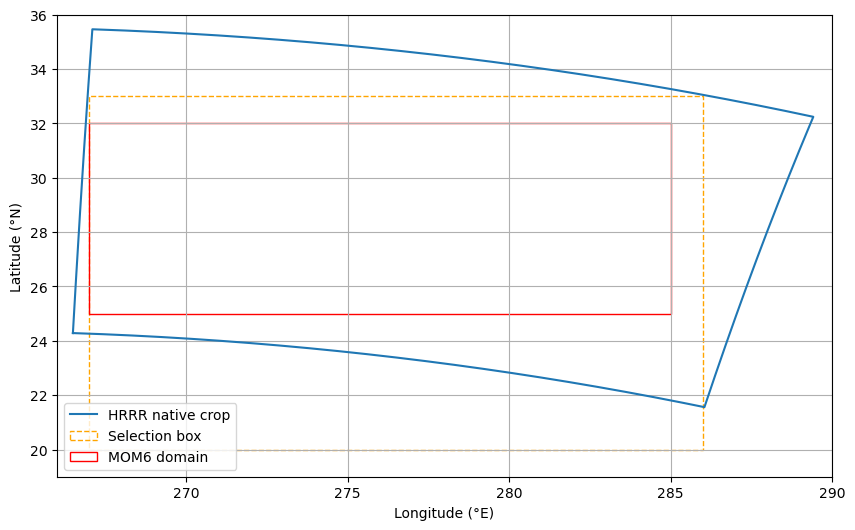

In [5]:
boundary_lon = np.r_[lon[0, :], lon[1:, -1], lon[-1, -2::-1], lon[-2:0:-1, 0]]
boundary_lat = np.r_[lat[0, :], lat[1:, -1], lat[-1, -2::-1], lat[-2:0:-1, 0]]
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(np.r_[boundary_lon, boundary_lon[0]], np.r_[boundary_lat, boundary_lat[0]], label='HRRR native crop')
ax.add_patch(Rectangle((WEST, SOUTH), EAST-WEST, NORTH-SOUTH, fill=False,
                       edgecolor='orange', linestyle='--', label='Selection box'))
ax.add_patch(Rectangle((MODEL_WEST, MODEL_SOUTH), MODEL_EAST-MODEL_WEST,
                       MODEL_NORTH-MODEL_SOUTH, fill=False, edgecolor='red', label='MOM6 domain'))
ax.set(xlabel='Longitude (°E)', ylabel='Latitude (°N)', xlim=(266, 290), ylim=(19, 36))
ax.legend(); ax.grid(); plt.show()

test_lon, test_lat = np.meshgrid(np.linspace(MODEL_WEST, MODEL_EAST, 181),
                                 np.linspace(MODEL_SOUTH, MODEL_NORTH, 71))
outline = MplPath(np.column_stack((boundary_lon, boundary_lat)), closed=True)
assert outline.contains_points(np.column_stack((test_lon.ravel(), test_lat.ravel()))).all(),     'The proposed MOM6 rectangle extends outside the native HRRR crop'

## 2. Download five analyses and rotate winds if required

`GRIB_uvRelativeToGrid` is checked for every hour. Both wind components are rotated together using the geographic azimuths of the HRRR grid axes. Every field must match the same cropped grid and contain finite values.

In [6]:
geod = Geod(ellps='WGS84')
az_x = np.empty((ny, nx), dtype=np.float64)
az_y = np.empty((ny, nx), dtype=np.float64)
az_x[:, :-1], _, _ = geod.inv(lon[:, :-1], lat[:, :-1], lon[:, 1:], lat[:, 1:])
az_x[:, -1] = az_x[:, -2]
az_y[:-1, :], _, _ = geod.inv(lon[:-1, :], lat[:-1, :], lon[1:, :], lat[1:, :])
az_y[-1, :] = az_y[-2, :]
sx, cx = np.sin(np.deg2rad(az_x)), np.cos(np.deg2rad(az_x))
sy, cy = np.sin(np.deg2rad(az_y)), np.cos(np.deg2rad(az_y))
assert np.nanmin(sx) > 0 and np.nanmin(cy) > 0, 'Unexpected axis direction; inspect geometry'
assert np.nanmax(np.abs(sx * sy + cx * cy)) < 0.05, 'HRRR grid axes are unexpectedly nonorthogonal'

def earth_winds(u, v):
    if u_flag == 0:
        return u, v
    return u * sx + v * sy, u * cx + v * cy

print('Rotation ready; GRIB flag:', u_flag)

Rotation ready; GRIB flag: 1


In [7]:
hourly = {key: [] for key in FIELD}
metadata = {}

for hour in range(N_HOURS):
    valid = START + timedelta(hours=hour)
    h = h0 if hour == 0 else Herbie(valid, model='hrrr', product='sfc', fxx=0, save_dir=CACHE)
    fields = {}
    for key, search in FIELD.items():
        da = ({'U_10': u0, 'V_10': v0}[key] if hour == 0 and key in ('U_10', 'V_10')
              else read_field(h, search))
        np.testing.assert_allclose(da.latitude.values[ys, xs], lat, atol=1e-5)
        np.testing.assert_allclose(da.longitude.values[ys, xs] % 360.0, lon, atol=1e-5)
        values = np.asarray(da.values[ys, xs], dtype=np.float64)
        if not np.isfinite(values).all():
            raise ValueError(f'{key} contains missing HRRR values at {valid}')
        fields[key] = values
        metadata.setdefault(key, {name: da.attrs.get(name) for name in ('units', 'GRIB_units', 'GRIB_stepType')})
        if key in ('U_10', 'V_10'):
            assert wind_grid_flag(da, h, search) == u_flag, (key, valid)

    fields['U_10'], fields['V_10'] = earth_winds(fields['U_10'], fields['V_10'])
    for key, values in fields.items():
        hourly[key].append(values.astype('float32'))
    print(f'{valid:%Y-%m-%d %H:%M} UTC: all eight fields')

data = {key: np.stack(hourly[key]) for key in FIELD}
assert all(a.shape == (N_HOURS, ny, nx) for a in data.values())
for key, a in data.items():
    print(key, metadata[key], 'range:', (float(a.min()), float(a.max())))

2024-09-20 00:00 UTC: all eight fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Sep-20 01:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-09-20 01:00 UTC: all eight fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Sep-20 02:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-09-20 02:00 UTC: all eight fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Sep-20 03:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-09-20 03:00 UTC: all eight fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Sep-20 04:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-09-20 04:00 UTC: all eight fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Sep-20 05:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-09-20 05:00 UTC: all eight fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Sep-20 06:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-09-20 06:00 UTC: all eight fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Sep-20 07:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-09-20 07:00 UTC: all eight fields
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Sep-20 08

Check the printed source units and GRIB step types against the desired interface before proceeding. This cell stops on unfamiliar units and implausible ranges; it deliberately does not silently convert units or reinterpret forecast accumulations.

In [8]:
def unit_key(value):
    return (str(value).lower().replace(' ', '').replace('**', '').replace('^', '')
            .replace('−', '-').replace('·', ''))

accepted = {
    'U_10': {'ms-1', 'm/s'}, 'V_10': {'ms-1', 'm/s'},
    'T_2': {'k'}, 'Q_2': {'kgkg-1', 'kg/kg'},
    'SLP_': {'pa'}, 'SWDN': {'wm-2', 'w/m2'},
    'LWDN': {'wm-2', 'w/m2'},
    'PRATE': {'kgm-2s-1', 'kg/m2/s'},
}
for key, attrs in metadata.items():
    supplied = [attrs.get('GRIB_units'), attrs.get('units')]
    assert any(unit_key(u) in accepted[key] for u in supplied if u is not None), (key, supplied)
assert 240 < float(data['T_2'].min()) < float(data['T_2'].max()) < 330
assert 0 <= float(data['Q_2'].min()) < float(data['Q_2'].max()) < 0.05
assert 85000 < float(data['SLP_'].min()) < float(data['SLP_'].max()) < 110000
assert float(data['PRATE'].min()) >= 0
print('Units and basic ranges pass. Review stepType above, especially SWDN/LWDN/PRATE.')

Units and basic ranges pass. Review stepType above, especially SWDN/LWDN/PRATE.


## 3. Write native-grid HRRR data and source ESMF mesh

Centers and corner nodes use the same `(y, x)` ordering as the NetCDF variables. The mesh has 1-based counterclockwise quad connectivity and all source cells active. We are **not** regridding HRRR onto TL319/JRA.

In [9]:
def centers_to_corners(a):
    ny0, nx0 = a.shape
    ext = np.empty((ny0 + 2, nx0 + 2), dtype='float64')
    ext[1:-1, 1:-1] = a
    ext[0, 1:-1] = 2*a[0, :] - a[1, :]
    ext[-1, 1:-1] = 2*a[-1, :] - a[-2, :]
    ext[:, 0] = 2*ext[:, 1] - ext[:, 2]
    ext[:, -1] = 2*ext[:, -2] - ext[:, -3]
    return 0.25 * (ext[:-1, :-1] + ext[1:, :-1] + ext[:-1, 1:] + ext[1:, 1:])

unwrapped = np.rad2deg(np.unwrap(np.unwrap(np.deg2rad(lon), axis=1), axis=0))
assert np.median(np.diff(unwrapped, axis=1)) > 0
assert np.median(np.diff(lat, axis=0)) > 0
corner_lon, corner_lat = centers_to_corners(unwrapped), centers_to_corners(lat)
nodes = np.arange(1, (ny + 1)*(nx + 1) + 1, dtype='int32').reshape(ny + 1, nx + 1)
conn = np.stack((nodes[:-1, :-1], nodes[:-1, 1:], nodes[1:, 1:], nodes[1:, :-1]),
                axis=-1).reshape(ny*nx, 4)

mesh = xr.Dataset(
    data_vars={
        'nodeCoords': (('nodeCount', 'coordDim'),
                       np.column_stack(((corner_lon % 360).ravel(), corner_lat.ravel())), {'units': 'degrees'}),
        'elementConn': (('elementCount', 'maxNodePElement'), conn, {'start_index': 1}),
        'numElementConn': (('elementCount',), np.full(ny*nx, 4, dtype='int32')),
        'centerCoords': (('elementCount', 'coordDim'),
                         np.column_stack((lon.ravel(), lat.ravel())), {'units': 'degrees'}),
        'elementMask': (('elementCount',), np.ones(ny*nx, dtype='int32')),
        'origGridDims': (('origGridRank',), np.array([nx, ny], dtype='int32')),
    }, attrs={'gridType': 'unstructured', 'version': '0.9',
              'conventions': 'ESMFMESH', 'title': 'Native rectangular HRRR Lambert crop'})
mesh.to_netcdf(HRRR_MESH, format='NETCDF4_CLASSIC',
               encoding={name: {'_FillValue': None} for name in mesh.variables})
print(HRRR_MESH, 'elements:', ny*nx)

/glade/work/hmnguyen/hrrr_forcing/florida_storm_004hrrrFull/HRRR_ESMFmesh.nc elements: 294279


In [10]:
details = {
    'U_10': ('10 m geographic eastward wind', 10),
    'V_10': ('10 m geographic northward wind', 10),
    'T_2': ('2 m air temperature', 2),
    'Q_2': ('2 m specific humidity', 2),
    'SLP_': ('mean sea level pressure', None),
    'SWDN': ('surface downward shortwave radiation', None),
    'LWDN': ('surface downward longwave radiation', None),
    'PRATE': ('surface precipitation rate', None),
}
variables = {}
for key, values in data.items():
    description, height = details[key]
    attrs = {'units': UNITS[key], 'long_name': description,
             'HRRR_stepType': str(metadata[key].get('GRIB_stepType'))}
    if height is not None:
        attrs['reference_height_m'] = height
    variables[key] = (('time', 'y', 'x'), values, attrs)

forcing = xr.Dataset(
    data_vars=variables,
    coords={
        'time': (('time',), np.arange(N_HOURS, dtype='float64'),
                 {'units': f'hours since {START:%Y-%m-%d %H:%M:%S}', 'calendar': 'gregorian'}),
        'latitude': (('y', 'x'), lat, {'units': 'degrees_north'}),
        'longitude': (('y', 'x'), lon, {'units': 'degrees_east'}),
    }, attrs={'source': 'HRRR sfc f00 analysis on native Lambert grid',
              'wind_orientation': 'geographic east/north',
              'purpose': 'short DATM interface test; thermodynamic height and flux timing need review'})
forcing.to_netcdf(HRRR_FILE, format='NETCDF4_CLASSIC',
                  encoding={k: {'zlib': True, 'complevel': 2,
                                '_FillValue': np.float32(1e20)} for k in FIELD})
print(HRRR_FILE)

/glade/work/hmnguyen/hrrr_forcing/florida_storm_004hrrrFull/HRRR_DATM_20240920_20241022.nc


In [11]:
with xr.open_dataset(HRRR_FILE, decode_times=False) as check, \
     xr.open_dataset(HRRR_MESH, decode_times=False) as checkmesh:
    assert set(FIELD) <= set(check.data_vars)
    for key in FIELD:
        assert check[key].dims == ('time', 'y', 'x')
        assert check[key].shape == (N_HOURS, ny, nx)
    np.testing.assert_array_equal(check.time.values, np.arange(N_HOURS))
    assert check.time.attrs['calendar'].lower() == 'gregorian'
    np.testing.assert_allclose(checkmesh.centerCoords.values[:, 0], lon.ravel())
    np.testing.assert_allclose(checkmesh.centerCoords.values[:, 1], lat.ravel())
    np.testing.assert_array_equal(checkmesh.origGridDims.values, [nx, ny])
    assert checkmesh.sizes['elementCount'] == ny*nx
    assert np.all(checkmesh.elementMask.values == 1)
    print('Eight fields, hourly time, and source mesh ordering verified.')

Eight fields, hourly time, and source mesh ordering verified.


## CHECKPOINT A — create and configure `florida_storm_004hrrrFull` in CrocoDash

Now return to the **CrocoDash case-generation notebook you used successfully for 003**. Use its existing `Grid`, component/case constructor, generation, and setup calls; edit only the new case/input name and simulation dates. Keep the same **1/16° grid** (267–285°E, 25–32°N) and the same MOM6+DATM component configuration. Set the CrocoDash case name to **`florida_storm_004hrrrFull`** (and its input directory name to the corresponding new 004 name). Use a 2024 GLORYS IC/OBC interval that covers this run, e.g.:

```python
case.configure_forcings(
    date_range=['2024-10-09 00:00:00', '2024-10-10 00:00:00'],
    boundaries=['south', 'north', 'west', 'east'],
    product_name='GLORYS',
    function_name='get_glorys_data_from_rda',
)
case.process_forcings()
```

Complete the same case generation/setup steps used for 003 until the **new** case directory has `env_run.xml`, `user_nl_datm_streams`, and `CaseDocs/datm.streams.xml`. Do **not** build or submit yet. CrocoDash may regenerate the `StreamYears` overrides during `configure_forcings`; the next cells remove that marked block and write all eight HRRR overrides. If you call `configure_forcings` again later, rerun the override cell and `./preview_namelists`.

In [12]:
assert CASE.is_dir(), f'First generate the new CrocoDash case: {CASE}'
assert (CASE / 'env_run.xml').is_file()
assert (CASE / 'CaseDocs/datm.streams.xml').is_file(), \
    'Set up the case and run preview_namelists once if CaseDocs does not yet exist'
entries = {e.get('id'): e.get('value') for e in ET.parse(CASE / 'env_run.xml').iter('entry')}
print({k: entries.get(k) for k in ('CALENDAR', 'RUN_STARTDATE', 'OCN_DOMAIN_MESH', 'ATM_DOMAIN_MESH')})
assert entries.get('CALENDAR', '').lower() in ('gregorian', 'standard')
ocean_mesh = Path(entries['OCN_DOMAIN_MESH'])
assert ocean_mesh.is_file(), ocean_mesh
assert '004' in str(ocean_mesh), 'OCN_DOMAIN_MESH unexpectedly points to an older case'

{'CALENDAR': 'GREGORIAN', 'RUN_STARTDATE': '2024-09-20', 'OCN_DOMAIN_MESH': '/glade/work/hmnguyen/crocodile2026/croc_input/florida_storm_004hrrrFull/ocn/ESMF_mesh_florida_milton_hrrr4_full_023ad2.nc', 'ATM_DOMAIN_MESH': '/glade/campaign/cesm/cesmdata/inputdata/share/meshes/TL319_151007_ESMFmesh.nc'}


## 4. Make the regional all-active ATM model mesh

This is deliberately **different** from the HRRR source mesh. Copy the new case's ocean mesh and set every ATM model element active, including coastal land cells. The ocean mesh and its wet/dry mask are unchanged. This incorporates the fix that resolved `42 nans found in Sa_dens` in 003.

In [13]:
assert ocean_mesh.resolve() != ATM_MESH.resolve()
shutil.copy2(ocean_mesh, ATM_MESH)
with Dataset(ATM_MESH, 'r+') as nc:
    mask = nc.variables['elementMask']
    mask[:] = np.ones(mask.shape, dtype=mask.dtype)
with Dataset(ATM_MESH) as atm, Dataset(ocean_mesh) as ocn:
    atm_mask = np.asarray(atm.variables['elementMask'][:])
    ocn_mask = np.asarray(ocn.variables['elementMask'][:])
    assert np.all(atm_mask == 1)
    assert np.any(ocn_mask == 1)
    print('Ocean mask:', dict(zip(*[v.tolist() for v in np.unique(ocn_mask, return_counts=True)])))
    print('ATM mesh:', ATM_MESH, 'elements:', len(atm_mask), 'all active')
    centers = np.asarray(ocn.variables['centerCoords'][:])
    wet = centers[ocn_mask == 1]
    wet[:, 0] %= 360
    outside = ~outline.contains_points(wet, radius=1e-9)
    assert outside.sum() == 0, f'{outside.sum()} wet ocean cells outside HRRR crop'

Ocean mask: {0: 10392, 1: 21864}
ATM mesh: /glade/work/hmnguyen/hrrr_forcing/florida_storm_004hrrrFull/Florida_regional_ATM_ESMFmesh.nc elements: 32256 all active


## 5. Replace **all eight** JRA data streams in the case override file

The stream *names* keep `CORE_IAF_JRA_1p5_2023` because they identify the existing CDEPS stream slots. Their `datafiles`, `meshfile`, dates, and `datavars` will all be HRRR after preview. Read actual `Sa_*` target names from the case's generated XML instead of guessing them. Any older 003/JRA hand-edited overrides in the fresh 004 case stop this cell.

In [14]:
stream_xml = CASE / 'CaseDocs/datm.streams.xml'
root = ET.parse(stream_xml).getroot()
sources = {
    'PREC': 'PRATE', 'LWDN': 'LWDN', 'SWDN': 'SWDN',
    'Q_10': 'Q_2', 'SLP_': 'SLP_', 'T_10': 'T_2',
    'U_10': 'U_10', 'V_10': 'V_10',
}
streams = {}
for item in root.iter('stream_info'):
    name = item.get('name', '')
    suffix = name.rsplit('.', 1)[-1]
    if name.startswith('CORE_IAF_JRA_1p5_2023.') and suffix in sources:
        assert suffix not in streams, ('duplicate stream', suffix)
        pairs = [(var.text or '').split() for var in item.findall('./datavars/var')]
        assert len(pairs) == 1 and len(pairs[0]) == 2, (name, pairs)
        streams[suffix] = (name, pairs[0][1])
assert set(streams) == set(sources), ('Missing DATM slots', set(sources) - set(streams))
assert streams['U_10'][1] == 'Sa_u' and streams['V_10'][1] == 'Sa_v'
for field, (name, target) in streams.items():
    print(f'{name}: {sources[field]} -> {target}')

CORE_IAF_JRA_1p5_2023.GCGCS.PREC: PRATE -> Faxa_prec
CORE_IAF_JRA_1p5_2023.GISS.LWDN: LWDN -> Faxa_lwdn
CORE_IAF_JRA_1p5_2023.GISS.SWDN: SWDN -> Faxa_swdn
CORE_IAF_JRA_1p5_2023.NCEP.Q_10: Q_2 -> Sa_shum
CORE_IAF_JRA_1p5_2023.NCEP.SLP_: SLP_ -> Sa_pslv
CORE_IAF_JRA_1p5_2023.NCEP.T_10: T_2 -> Sa_tbot
CORE_IAF_JRA_1p5_2023.NCEP.U_10: U_10 -> Sa_u
CORE_IAF_JRA_1p5_2023.NCEP.V_10: V_10 -> Sa_v


In [15]:
override_file = CASE / 'user_nl_datm_streams'
existing = override_file.read_text() if override_file.exists() else ''
auto_block = re.compile(
    r'(?ms)^! >>> CrocoDash configure_forcings: StreamYears[^\n]*\n'
    r'.*?^! <<< CrocoDash configure_forcings: StreamYears[^\n]*(?:\n|$)'
)
own_block = re.compile(
    r'(?ms)^! >>> HRRR Full 004[^\n]*\n.*?^! <<< HRRR Full 004[^\n]*(?:\n|$)'
)
cleaned, auto_count = auto_block.subn('', existing)
cleaned, old_count = own_block.subn('', cleaned)
if 'CrocoDash configure_forcings: StreamYears' in cleaned or 'HRRR Full 004' in cleaned:
    raise ValueError('Unmatched stream block markers: inspect user_nl_datm_streams')
for line in cleaned.splitlines():
    stripped = line.strip()
    if any(stripped.startswith(name + ':') for name, _ in streams.values()):
        raise ValueError(f'Conflicting manual stream override outside known blocks: {line}')
assert auto_count <= 1 and old_count <= 1

lines = ['! >>> HRRR Full 004 (regenerate after any configure_forcings call)']
for field, (name, target) in streams.items():
    for key, value in {
        'taxmode': 'limit', 'tintalgo': 'linear', 'readmode': 'single',
        'mapalgo': 'bilinear', 'year_first': '2024',
        'year_last': '2024', 'year_align': '2024',
        'meshfile': str(HRRR_MESH), 'datafiles': str(HRRR_FILE),
        'datavars': f'{sources[field]} {target}',
    }.items():
        lines.append(f'{name}:{key} = {value}')
lines.append('! <<< HRRR Full 004')
override_file.write_text(cleaned.rstrip() + '\n\n' + '\n'.join(lines) + '\n')
print('Replaced CrocoDash StreamYears blocks:', auto_count)
print('Updated prior HRRR Full block:', old_count)
print('Wrote 8 complete HRRR stream overrides:', override_file)

Replaced CrocoDash StreamYears blocks: 0
Updated prior HRRR Full block: 0
Wrote 8 complete HRRR stream overrides: /glade/u/home/hmnguyen/work/crocodile2026/croc_cases/florida_storm_004hrrrFull/user_nl_datm_streams


## CHECKPOINT B — configure case XML, then generate namelists (terminal)

In a **terminal**, from the newly generated 004 case directory, run the following. `ATM_DOMAIN_MESH` points to the all-active *regional model* mesh; stream `meshfile` points to the distinct HRRR *source* mesh. Keep `OCN_DOMAIN_MESH` unchanged. Use the same scheduler/project options as your successful 003 case.

```bash
cd /glade/u/home/hmnguyen/work/crocodile2026/croc_cases/florida_storm_004hrrrFull
./xmlchange ATM_DOMAIN_MESH=/glade/work/hmnguyen/hrrr_forcing/florida_storm_004hrrrFull/Florida_regional_ATM_ESMFmesh.nc
./xmlchange RUN_STARTDATE=2024-10-09 STOP_OPTION=nhours STOP_N=3 HIST_OPTION=nhours HIST_N=1
./preview_namelists
```

Then run **the next notebook cell**. Fix any failed assertion before building. In particular, all eight source datafiles must be HRRR; a JRA file anywhere in those eight streams means the override was not applied.

In [18]:
run_entries = {e.get('id'): e.get('value') for e in ET.parse(CASE / 'env_run.xml').iter('entry')}
assert run_entries.get('ATM_DOMAIN_MESH') == str(ATM_MESH)
assert run_entries.get('OCN_DOMAIN_MESH') == str(ocean_mesh)
assert run_entries.get('RUN_STARTDATE') == '2024-09-20'
assert run_entries.get('STOP_OPTION') == 'nmonths'
assert int(run_entries.get('STOP_N', '-1')) == STOP_N

datm_in = (CASE / 'CaseDocs/datm_in').read_text()
for name in ('model_meshfile', 'model_maskfile'):
    match = re.search(rf"(?im)^\s*{name}\s*=\s*['\"]([^'\"]+)['\"]", datm_in)
    assert match, f'{name} missing from CaseDocs/datm_in'
    print(name, '=', match.group(1))
    assert Path(match.group(1)) == ATM_MESH

generated = ET.parse(CASE / 'CaseDocs/datm.streams.xml').getroot()
seen = set()
for stream in generated.iter('stream_info'):
    name = stream.get('name', '')
    suffix = name.rsplit('.', 1)[-1]
    if not name.startswith('CORE_IAF_JRA_1p5_2023.') or suffix not in sources:
        continue
    assert suffix not in seen, suffix
    seen.add(suffix)
    files = [node.text for node in stream.findall('./datafiles/file')]
    pairs = [(node.text or '').split() for node in stream.findall('./datavars/var')]
    assert files == [str(HRRR_FILE)], (suffix, files)
    assert stream.findtext('meshfile') == str(HRRR_MESH), suffix
    assert pairs == [[sources[suffix], streams[suffix][1]]], (suffix, pairs)
    assert stream.findtext('taxmode') == 'limit'
    assert stream.findtext('tintalgo') == 'linear'
    assert stream.findtext('mapalgo') == 'bilinear'
    assert [stream.findtext(k) for k in ('year_first','year_last','year_align')] == ['2024']*3
    print(f'{suffix:5s} {pairs[0][0]:5s} -> {pairs[0][1]:10s} : {files[0]}')
assert seen == set(sources), seen
print('All eight streams use HRRR. Regional ATM model mesh verified. Ready to build.')

model_meshfile = /glade/work/hmnguyen/hrrr_forcing/florida_storm_004hrrrFull/Florida_regional_ATM_ESMFmesh.nc
model_maskfile = /glade/work/hmnguyen/hrrr_forcing/florida_storm_004hrrrFull/Florida_regional_ATM_ESMFmesh.nc
PREC  PRATE -> Faxa_prec  : /glade/work/hmnguyen/hrrr_forcing/florida_storm_004hrrrFull/HRRR_DATM_20240920_20241022.nc
LWDN  LWDN  -> Faxa_lwdn  : /glade/work/hmnguyen/hrrr_forcing/florida_storm_004hrrrFull/HRRR_DATM_20240920_20241022.nc
SWDN  SWDN  -> Faxa_swdn  : /glade/work/hmnguyen/hrrr_forcing/florida_storm_004hrrrFull/HRRR_DATM_20240920_20241022.nc
Q_10  Q_2   -> Sa_shum    : /glade/work/hmnguyen/hrrr_forcing/florida_storm_004hrrrFull/HRRR_DATM_20240920_20241022.nc
SLP_  SLP_  -> Sa_pslv    : /glade/work/hmnguyen/hrrr_forcing/florida_storm_004hrrrFull/HRRR_DATM_20240920_20241022.nc
T_10  T_2   -> Sa_tbot    : /glade/work/hmnguyen/hrrr_forcing/florida_storm_004hrrrFull/HRRR_DATM_20240920_20241022.nc
U_10  U_10  -> Sa_u       : /glade/work/hmnguyen/hrrr_forcing/flor

## CHECKPOINT C — build and submit (terminal)

Only after the verification cell passes, run in the **same new 004 case directory**:

```bash
./case.build
./case.submit
```

If the Derecho workflow used for 003 requires an interactive build allocation, use that same allocation workflow and run `./case.build` there. During startup the `atm.log` should enumerate eight HRRR streams. Check `med.log` for finite `Sa_dens`; `atm.log` alone is not sufficient. In the coupler history, inspect `atmImp_Sa_u` **and** `atmImp_Sa_v` at 01 UTC. These variables may be 1D over unstructured regional ocean elements; use the case ocean mesh `centerCoords` to plot them geographically.

This is a short plumbing test. Before extending the Milton hindcast, resolve `T_2/Q_2` reference heights and the meaning/time bounds of f00 `SWDN/LWDN/PRATE` in the coupled flux path; extend HRRR forcing and GLORYS IC/OBC together. WW3 and tides come later.